# IND320 Project Part 1

Reservoir data analysis with Pandas, Matplotlib, and Streamlit.

## Project description

This project explores the reservoir data supplied for IND320. The notebook documents data preparation and plots, while the Streamlit application provides an interactive view. The real reservoirs.csv file must be placed in the project root.

## GitHub and Streamlit links

- GitHub repository: https://github.com/scerty/ind320-abdullah
- Streamlit app: https://ind320-abdullah-97txw7dyrwve3zvbbaw9mr.streamlit.app/

## AI usage

Placeholder: Describe which parts of the work used AI assistance, what was checked manually, and how the final code and explanations were verified.

## Import libraries

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

## Load reservoirs.csv

In [23]:
data_path = Path("reservoirs.csv")
if not data_path.exists():
    raise FileNotFoundError(
        "Add the real reservoirs.csv file to the project root before running the notebook."
    )

reservoir_data = pd.read_csv(data_path)
reservoir_data.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


## Rename columns

The CSV headers are not assumed in advance. This function cleans the actual headers into readable English display names while preserving their meaning.

In [24]:
# Rename the actual Norwegian headers into clear English labels.
column_name_map = {
    "dato_Id": "Date",
    "omrType": "Area Type",
    "omrnr": "Area Number",
    "iso_aar": "ISO Year",
    "iso_uke": "ISO Week",
    "fyllingsgrad": "Filling Percentage",
    "kapasitet_TWh": "Capacity (TWh)",
    "fylling_TWh": "Filled Volume (TWh)",
    "neste_Publiseringsdato": "Next Publication Date",
    "fyllingsgrad_forrige_uke": "Previous Week Filling Percentage",
    "endring_fyllingsgrad": "Change in Filling Percentage",
}
reservoir_data = reservoir_data.rename(
    columns={
        column: readable_name
        for column, readable_name in column_name_map.items()
        if column in reservoir_data.columns
    }
)
reservoir_data["Date"] = pd.to_datetime(reservoir_data["Date"])

# The file contains national, electricity-area, and water-area rows.
# Use the national aggregate for one clear time series in the plots.
national_data = reservoir_data
if {"Area Type", "Area Number"}.issubset(reservoir_data.columns):
    national_rows = reservoir_data[
        reservoir_data["Area Type"].eq("NO")
        & reservoir_data["Area Number"].eq(0)
    ]
    if not national_rows.empty:
        national_data = national_rows.copy()

# Sort the observations before drawing lines on the time axis.
national_data = national_data.sort_values("Date").reset_index(drop=True)

reservoir_data.head()

,Date,Area Type,Area Number,ISO Year,ISO Week,Filling Percentage,Capacity (TWh),Filled Volume (TWh),Next Publication Date,Previous Week Filling Percentage,Change in Filling Percentage
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


## Display the data

In [25]:
display(reservoir_data)

,Date,Area Type,Area Number,ISO Year,ISO Week,Filling Percentage,Capacity (TWh),Filled Volume (TWh),Next Publication Date,Previous Week Filling Percentage,Change in Filling Percentage
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
...,...,...,...,...,...,...,...,...,...,...,...
14872,2026-07-19,VASS,3,2026,29,0.796849,28.155403,22.435612,2026-07-29T13:00:00,0.794957,0.001892
14873,2026-09-06,VASS,3,2026,36,0.826252,28.155403,23.263466,2026-09-16T13:00:00,0.827641,-0.001389
14874,2026-08-30,VASS,3,2026,35,0.827718,28.155403,23.304743,2026-09-09T13:00:00,0.829898,-0.002180
14875,2026-09-06,VASS,1,2026,36,0.570397,36.044464,20.559645,2026-09-16T13:00:00,0.567087,0.003310


## Plot each column separately

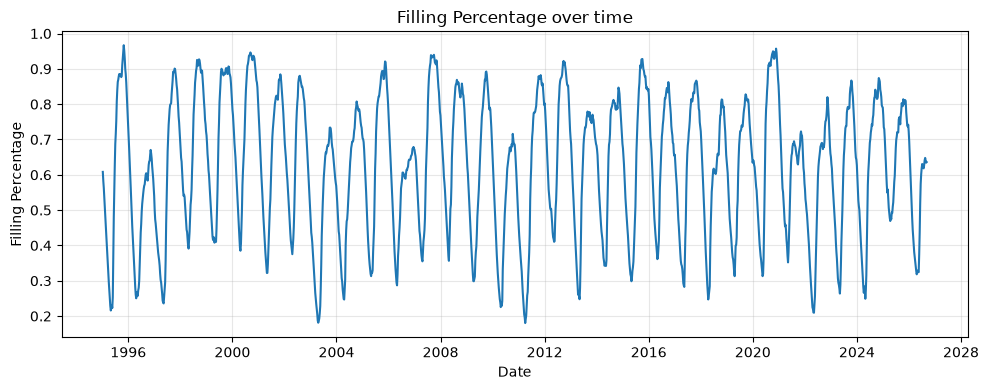

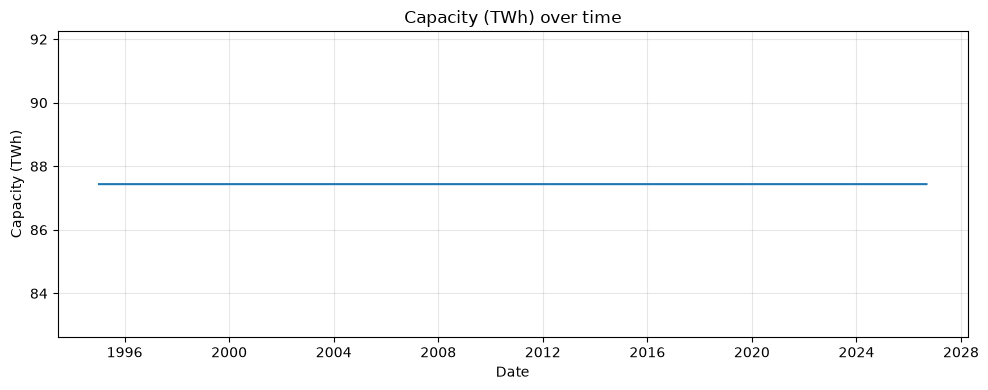

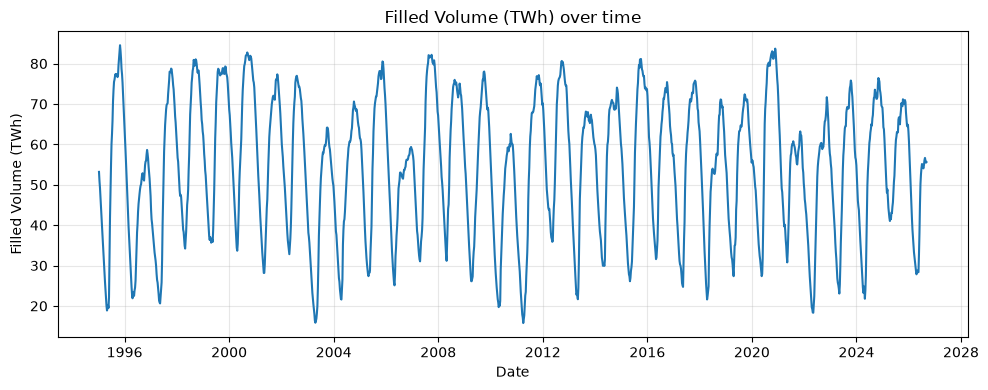

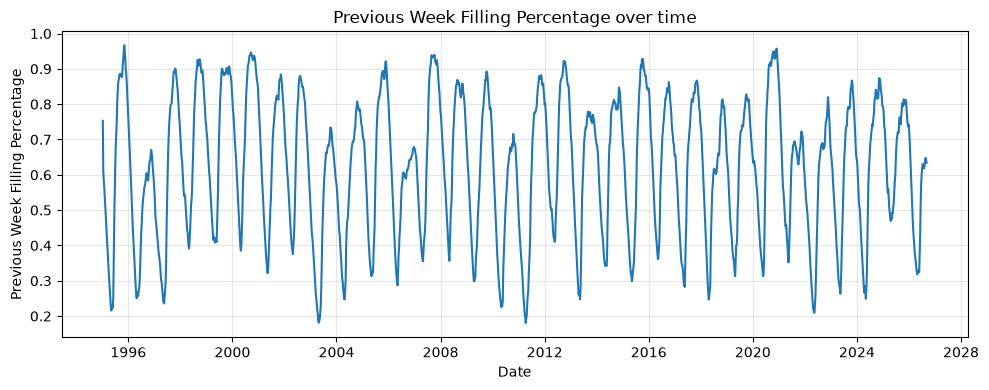

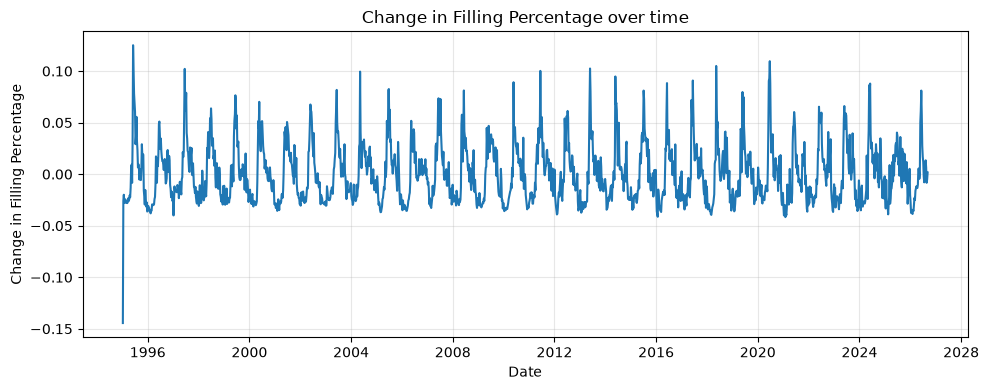

In [26]:
# Exclude identifiers such as area number and ISO week from the plotted measures.
identifier_columns = {"Area Number", "ISO Year", "ISO Week"}
numeric_columns = [
    column
    for column in national_data.select_dtypes(include="number").columns
    if column not in identifier_columns
]
if not numeric_columns:
    raise ValueError("No numeric reservoir measures were found in reservoirs.csv.")

# Plot every actual reservoir measure separately against the observation date.
for column in numeric_columns:
    plt.figure(figsize=(10, 4))
    plt.plot(national_data["Date"], national_data[column])
    plt.title(f"{column} over time")
    plt.xlabel("Date")
    plt.ylabel(column)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Plot all columns together

The data columns may use different units or scales. The comparison below normalizes each series to 100 at its first value, so the relative development can be compared without changing the original data.

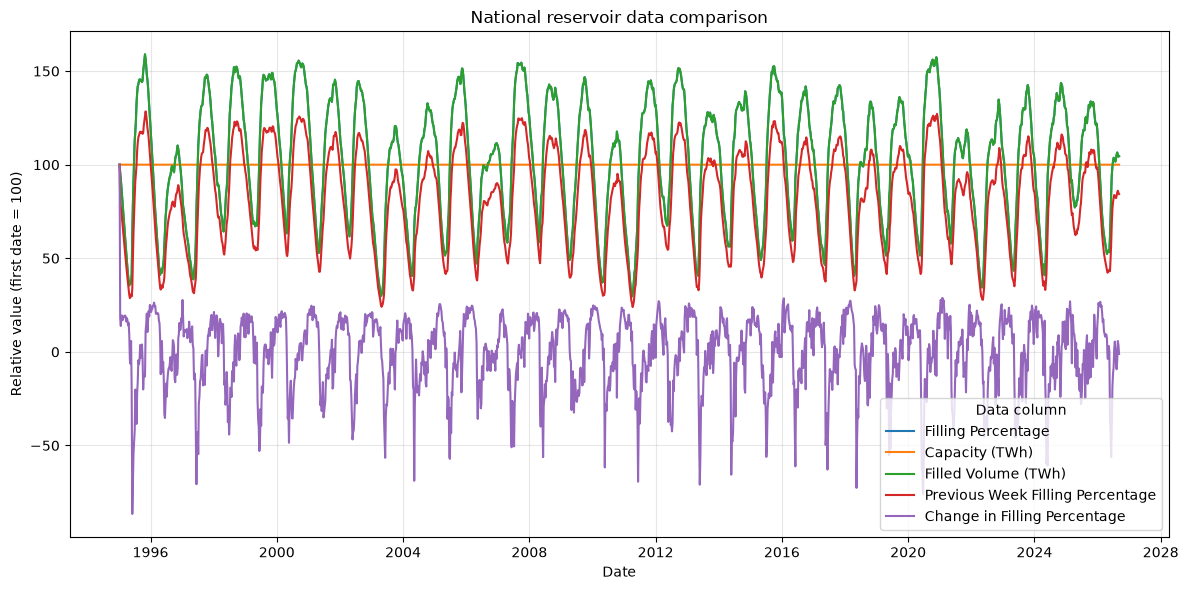

In [27]:
# Normalize each measure to its first national value for a readable comparison.
plot_data = national_data[numeric_columns].copy()
first_values = plot_data.iloc[0].replace(0, pd.NA)
normalized_data = plot_data.divide(first_values).multiply(100).fillna(plot_data)

plt.figure(figsize=(12, 6))
for column in numeric_columns:
    plt.plot(national_data["Date"], normalized_data[column], label=column)
plt.title("National reservoir data comparison")
plt.xlabel("Date")
plt.ylabel("Relative value (first date = 100)")
plt.legend(title="Data column")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Observations

Placeholder: Describe the main trends, peaks, changes, similarities, and differences you observe after running the notebook with the real course data.

## Compulsory work log

Placeholder: Write a 300-500 word work log describing the work completed, decisions made, problems encountered, how they were solved, and what remains to be done.